In [13]:
import pandas as pd
import numpy as np

#โหลด data ที่แบ่งไว้
data_dir = '../data/processed/HDFS'

train_df = pd.read_csv(f"{data_dir}/train.csv")
val_df = pd.read_csv(f"{data_dir}/val.csv")
test_df = pd.read_csv(f"{data_dir}/test.csv")

#ตรวจสอบความถูกต้อง
print(f'='*30)
print(f"Train Set: {len(train_df):,} แถว | มี Anomaly: {train_df['Label'].sum()} อัน ({train_df['Label'].mean()*100:.2f}%)")
print(f"Train Set: {len(val_df):,}   แถว | มี Anomaly: {val_df['Label'].sum()} อัน ({val_df['Label'].mean()*100:.2f}%)")
print(f"Train Set: {len(test_df):,}   แถว | มี Anomaly: {test_df['Label'].sum()} อัน ({test_df['Label'].mean()*100:.2f}%)")

print(f"\n==== ตัวอย่าง 10 แถวแรก ====")
print(train_df.head(10))

Train Set: 1,395 แถว | มี Anomaly: 48 อัน (3.44%)
Train Set: 299   แถว | มี Anomaly: 10 อัน (3.34%)
Train Set: 300   แถว | มี Anomaly: 10 อัน (3.33%)

==== ตัวอย่าง 10 แถวแรก ====
                    BlockId Sequence  Label
0  blk_-5224756755359850354       E1      0
1  blk_-3249711809227781266       E5      0
2  blk_-1868325377308234190       E1      0
3   blk_3386670145292909259       E4      0
4  blk_-4598246018559857954      E17      0
5   blk_2080318574920472813       E1      0
6    blk_391813102554451063       E3      0
7  blk_-1237539644269634790       E5      0
8    blk_429279891070363457       E3      0
9   blk_3050920587428079149       E5      0


In [22]:
from sklearn.feature_extraction.text import CountVectorizer

#สร้างตารางแปลง event id เป็นตารางนับความถี่ของ event id ที่เจอ
#โมเดล Logistic Regression จำเป็นต้องให้ทุก column มีจำนวนเท่ากัน ดังนั้นเลยทำเป็นตารางจากจำนวน event ที่มีแล้วนับเป็นความถี่
#token_pattern=r'\b\w+\b' สั่งให้มันมอง E1, E2, E32 เป็น 1 คำ (Token)
vectorizer = CountVectorizer(token_pattern=r'\b\w+\b')

#แปลง train set ให้ใช้ fit_transform เพื่อให้เรียนรู้ vocab และนับ
X_train = vectorizer.fit_transform(train_df['Sequence'])
Y_train = train_df['Label'].values

#แปลง test, val set ให้ใช้ transform เพื่อไม่ให้เรียนเพิ่ม
X_val = vectorizer.transform(val_df['Sequence'])
Y_val = val_df['Label'].values

X_test = vectorizer.transform(test_df['Sequence'])
Y_test = test_df['Label'].values

#ดูขนาด matrix ที่หาได้
print(f"=== ขนาดของตัวเลข Feature Matrix (ตารางตัวเลข) ===")
print(f"X_train: {X_train.shape} -> (จำนวน Session: {X_train.shape[0]}, จำนวน Event Type: {X_train.shape[1]})")
print(f"X_val:   {X_val.shape}  -> (จำนวน Session: {X_val.shape[0]},  จำนวน Event Type: {X_val.shape[1]})")
print(f"X_test:  {X_test.shape}  -> (จำนวน Session: {X_test.shape[0]},  จำนวน Event Type: {X_test.shape[1]})")

=== ขนาดของตัวเลข Feature Matrix (ตารางตัวเลข) ===
X_train: (1395, 16) -> (จำนวน Session: 1395, จำนวน Event Type: 16)
X_val:   (299, 16)  -> (จำนวน Session: 299,  จำนวน Event Type: 16)
X_test:  (300, 16)  -> (จำนวน Session: 300,  จำนวน Event Type: 16)


In [33]:
#ทดสอบโมเดล Logistic Regression (Supervised)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

#สร้างโมเดล Logistic Regression พร้อมป้องกัน Imbalance
lr_model = LogisticRegression(class_weight='balanced', random_state=42)

#เริ่มฝึกโมเดล
lr_model.fit(X_train,Y_train)

#ให้โมเดลทำข้อสอบ
y_pred_lr = lr_model.predict(X_test)

#วัดผลด้วย Classification Report (วัดจาก Recall, Predict, F1)
print(f"=== ผลประเมิน Logistic Regression บน Test Set ===")
print(classification_report(y_test,y_pred_lr, target_names=['Normal (0)', 'Anomaly (1)'],digits=4))

=== ผลประเมิน Logistic Regression บน Test Set ===
              precision    recall  f1-score   support

  Normal (0)     0.9663    0.5931    0.7350       290
 Anomaly (1)     0.0328    0.4000    0.0606        10

    accuracy                         0.5867       300
   macro avg     0.4995    0.4966    0.3978       300
weighted avg     0.9352    0.5867    0.7126       300



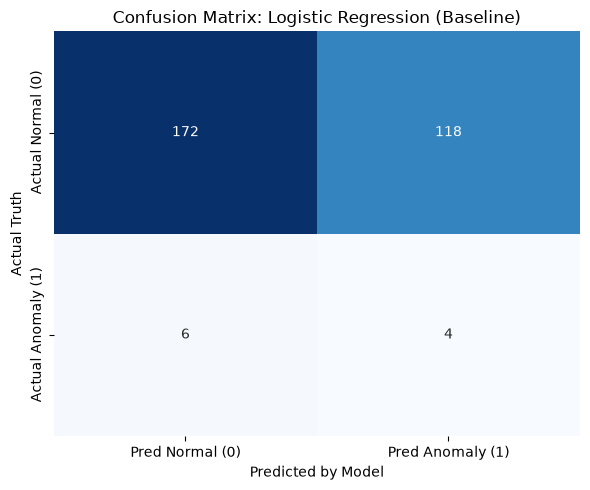

True Negative  (ปกติ แล้วทายว่าปกติ):      172 เคส
False Positive (ปกติ แต่ดันเตือนมั่ว):      118 เคส (False Alarm)
False Negative (คนร้ายบุก แต่โมเดลมองไม่เห็น): 6 เคส (หลุดรอด)
True Positive  (คนร้ายบุก แล้วจับได้จริง):   4 เคส


In [26]:
#คำนวณ Confusion Matrix
cm = confusion_matrix(y_test, y_pred_lr)

#วาด heatmap
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
           xticklabels=['Pred Normal (0)', 'Pred Anomaly (1)'],
           yticklabels=['Actual Normal (0)', 'Actual Anomaly (1)'])

plt.title('Confusion Matrix: Logistic Regression (Baseline)')
plt.ylabel('Actual Truth')
plt.xlabel('Predicted by Model')
plt.tight_layout()
plt.show()

#พิมพ์สรุป
tn, fp, fn, tp = cm.ravel()
print(f"True Negative  (ปกติ แล้วทายว่าปกติ):      {tn} เคส")
print(f"False Positive (ปกติ แต่ดันเตือนมั่ว):      {fp} เคส (False Alarm)")
print(f"False Negative (คนร้ายบุก แต่โมเดลมองไม่เห็น): {fn} เคส (หลุดรอด)")
print(f"True Positive  (คนร้ายบุก แล้วจับได้จริง):   {tp} เคส")

In [32]:
#ทดสอบการใช้ Isolation Forest Model (Unsupervised)
from sklearn.ensemble import IsolationForest

#สร้างโมเดล
# contamination=0.034 คือการบอกใบ้โมเดลคร่าวๆ จากตอนเราทำ EDA ว่าระบบนี้น่าจะมีตัวแปลกปลอมอยู่ราวๆ 3.4%
iso_model = IsolationForest(
    n_estimators=100,
    contamination=0.034,
    random_state=42
)

#ฝึกสอนโมเดล
iso_model.fit(X_train)

#ให้โมเดลทำนายบน Test set
# ข้อควรระวัง: Isolation Forest คืนค่า 1 = ปกติ, -1 = ผิดปกติ
raw_pred = iso_model.predict(X_test)

#แปลงค่าให้ตรงกับ format ที่ใช้
y_pred_iso = [1 if p == -1 else 0 for p in raw_pred]

#แสดงผลข้อมูล
print("==== ผลประเมิน Isolation Forest ====")
print(classification_report(y_test, y_pred_iso, target_names=['Normal (0)', 'Anomaly (1)'],digits=4))

==== ผลประเมิน Isolation Forest ====
              precision    recall  f1-score   support

  Normal (0)     0.9664    0.9931    0.9796       290
 Anomaly (1)     0.0000    0.0000    0.0000        10

    accuracy                         0.9600       300
   macro avg     0.4832    0.4966    0.4898       300
weighted avg     0.9342    0.9600    0.9469       300

